# Intro
Name:  

    Make_atmos_profile_and_albedo

Purpose:  

    Create the input libradtran files for creating the atmospheric profiles and surface albedo for ARCSIX
  
Input:

    none

Output:
   
    input files for libradtran 2.0 (uvspec) 
  
Keywords:

    none
  
Dependencies:

    - numpy
    - scipy : for saving and reading
    - mpl_toolkits for basemap, map plotting
    - pdb
    - datetime

  
Needed Files:

  - atmospheric profile file sample
  - surface albedo file sample
    
History:

    Written: Samuel LeBlanc, Santa Cruz, CA, 2026-11-13
             

# Prepare the python environment

In [1]:
import numpy as np
import scipy.io as sio
import os
import Run_libradtran as RL
import matplotlib.pyplot as plt

In [2]:
import load_utils as lu

In [3]:
fp = '/data2/ARCSIX/data/'
fp_atm = '/home/sam/libradtran/libRadtran-2.0.1/data/atmmod/'
fp_out = '/scratch/rtm/input/ARCSIX_v1/'

# Load the files

 Need to focus on the data found at the cloud wall timing, around 15:17 UTC to 15:46 UTC

In [47]:
os.listdir(fp)

['ARCSIX-HALO-images_G3_20240607_R0_F1.zip',
 'ARCSIX-TraceGas-O3_P3B_20240607_R0.ict',
 'ARCSIX-DLH-H2O_P3B_20240607_R0.ict',
 'ARCSIX-SSFR_P3B_20240607_R0.h5',
 'ARCSIX-AVAPS_G3_20240607162310_R1.ict',
 'ARCSIX-TraceGas-CO2_P3B_20240607_R0.ict',
 'MERRA2_400.inst3_3d_asm_Np.20240607.nc4',
 'MERRA2_400.tavg1_2d_slv_Nx.20240607.nc4',
 'ARCSIX-MetNav-KT19-10Hz_P3B_20240607_R0.ict',
 'ARCSIX-MetNav_P3B_20240607_R0.ict']

## Load the met data

In [33]:
met,met_header =lu.load_ict(fp+'ARCSIX-MetNav_P3B_20240607_R0.ict',return_header=True)

('Time_Start', 'Day_Of_Year', 'Latitude', 'Longitude', 'GPS_Altitude', 'Pressure_Altitude', 'Radar_Altitude', 'Ground_Speed', 'True_Air_Speed', 'Indicated_Air_Speed', 'Mach_Number', 'Vertical_Speed', 'True_Heading', 'Track_Angle', 'Drift_Angle', 'Pitch_Angle', 'Roll_Angle', 'Static_Air_Temp', 'Potential_Temp', 'DewFrost_Point', 'Total_Air_Temp', 'IR_Surf_Temp', 'Static_Pressure', 'Cabin_Pressure', 'Wind_Speed', 'Wind_Direction', 'UWindSpeed', 'VWindSpeed', 'Solar_Zenith_Angle', 'Aircraft_Sun_Elevation', 'Sun_Azimuth', 'Aircraft_Sun_Azimuth', 'Mixing_Ratio', 'Part_Press_Water_Vapor', 'Sat_Vapor_Press_H2O', 'Sat_Vapor_Press_Ice', 'Relative_Humidity')


In [28]:
met_header

['75,1001\n',
 'NASA Airborne Science Program\n',
 'National Suborbital Research Center [Bay Area Environmental Research Institute @ NASA Ames Research Center]\n',
 'N426NA Meteorological and Navigation (MetNav) Facility Instrumentation\n',
 'ARCSIX\n',
 '1,1\n',
 '2024,06,07,2024,12,01\n',
 '1\n',
 'Time_Start, seconds (from midnight UTC)\n',
 '36\n',
 '1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1\n',
 '-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999\n',
 'Day_Of_Year, day, None, calendar day beginning January 1\n',
 'Latitude, deg, Platform_Latitude_InSitu_None\n',
 'Longitude, deg, Platform_Longitude_InSitu_None\n',
 'GPS_Altitude, m, Platform_AltitudeMSL_InSitu_None\n',
 'Pressure_Altitude, ft, Platform_AltitudePressure_InSitu_None\n',
 'Radar_Altitude, ft, Platform_AltitudeAGL_InSitu_None\

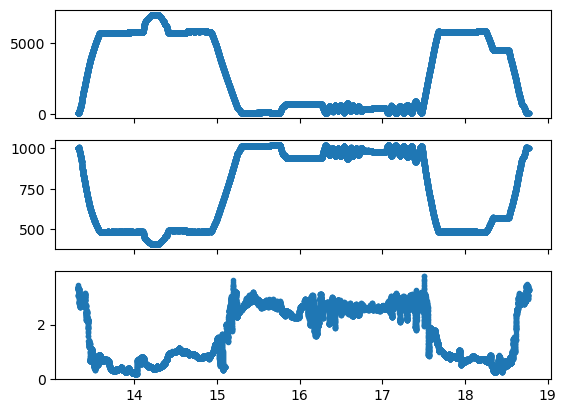

In [59]:
fig,ax = plt.subplots(3,1,sharex=True)
ax[0].plot(met['Time_Start']/3600.0,met['GPS_Altitude'],'.')
ax[1].plot(met['Time_Start']/3600.0,met['Static_Pressure'],'.')
ax[2].plot(met['Time_Start']/3600.0,met['Mixing_Ratio'],'.')


## Load the SSFR data

In [22]:
ssfr,ssfr_head = lu.load_hdf_h5py(fp+'ARCSIX-SSFR_P3B_20240607_R0.h5',all_values=True)

Reading file: /data2/ARCSIX/data/ARCSIX-SSFR_P3B_20240607_R0.h5
Outputting the Data subdatasets:
0: f_dn
1: f_up
2: gps_alt
3: gps_lat
4: gps_lon
5: time
6: wvl_dn
7: wvl_up
Running through data values: [########################################]100% -- Done! 
['f_dn', 'f_up', 'gps_alt', 'gps_lat', 'gps_lon', 'time', 'wvl_dn', 'wvl_up']


In [17]:
import importlib 
importlib.reload(lu)

<module 'load_utils' from '/home/sam/python_codes/load_utils.py'>

In [24]:
ssfr['time']/3600.0

array([13.31777778, 13.31805556, 13.31833333, ..., 18.76888889,
       18.76916667, 18.76944444], shape=(19627,))

## Load the atm uvspec data

In [34]:
atm = np.loadtxt(fp_atm+'afglss.dat')

In [37]:
atm.shape

(50, 9)

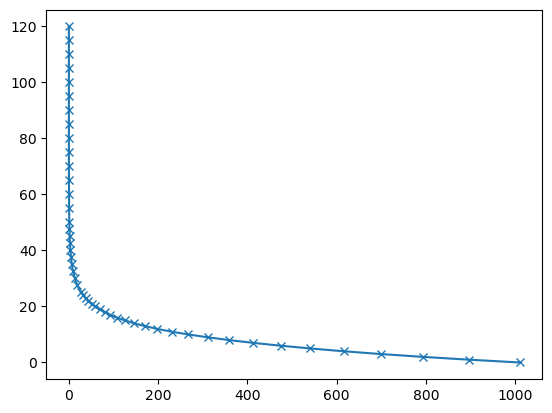

In [42]:
plt.figure()
plt.plot(atm[:,1],atm[:,0],'x-')


The first few lines of the subarctic summer atmos profile
> AFGL atmospheric constituent profile. subarctic summer. ( AFGL-TR-86-0110)       
>     z(km)      p(mb)        T(K)    air(cm-3)    o3(cm-3)     o2(cm-3)    h2o(cm-3)    co2(cm-3)     no2(cm-3)
>    120.000     0.00002     380.000 4.307612E+11 2.155500E+02 3.125475E+10 8.622001E+04 1.508850E+07 6.509610E+01

In [64]:
def gas_law(p,t):
    # p in mb
    # T in Kelvin
    R = 8.314           # Joule/mol/Kelvin
    Na= 6.02297e23 # molecules/mol
    return p/t/R*Na/10000.0

In [100]:
def h2o_mass_to_number_density(w_g_kg, p_mb, t_k):
    # Convert g/kg to dimensionless volume mixing ratio (mol/mol)
    M_dry = 28.97    # g/mol
    M_h2o = 18.015   # g/mol
    vmr = (w_g_kg / 1000.0) * (M_dry / M_h2o)
    
    # Multiply by total air number density (#/cm^3)
    n_air = gas_law(p_mb, t_k)
    return vmr * n_air

## Load the drop sonde data

In [48]:
sonde,sonde_hdr = lu.load_ict(fp+'ARCSIX-AVAPS_G3_20240607162310_R1.ict',return_header=True)

('Time_Start', 'ElaspedTime', 'Pressure', 'Temperature', 'RH', 'WindSpeed', 'WindDir', 'Latitude', 'Longitude', 'Pressure_Altitude', 'GPS_Altitude', 'Dewpoint', 'U_wind', 'V_wind', 'W_wind', 'DescentRate', 'MixingRatio', 'Theta', 'Theta_e', 'Theta_v', 'T_virtual')


In [49]:
sonde_hdr

['119,1001\n',
 'Thornhill, Lee\n',
 'NASA Langley\n',
 'AVAPS NRD41\n',
 'ARCSIX\n',
 '1,1\n',
 '2024,06,07,2025,10,28\n',
 '0.25\n',
 'Time_Start, seconds, Time_Start, Starting time of the sampling period in UTC seconds from midnight\n',
 '20\n',
 '1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1\n',
 '-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999,-9999\n',
 'ElaspedTime, seconds, None, Starting time of the sampling period from the launch\n',
 'Pressure, mb, Met_StaticPressure_InSitu_None, Static air pressure\n',
 'Temperature, deg C, Met_StaticAirTemperature_InSitu_None, Static air Temperature\n',
 'RH, %, Met_RelativeHumidityWater_InSitu_None, Relative humidity over water\n',
 'WindSpeed, m/s, Met_WindSpeed_InSitu_None, Wind Speed\n',
 'WindDir, deg, Met_WindDirection_InSitu_None, Wind Direction\n',
 'Latitude, deg, Platform_Latitude_InSitu_None, Sonde latitude\n',
 'Longitude, deg, Platform_longitude_InSitu_None, Sonde lon

Text(0.5, 0, 'H20 Mixing ratio [g/kg]')

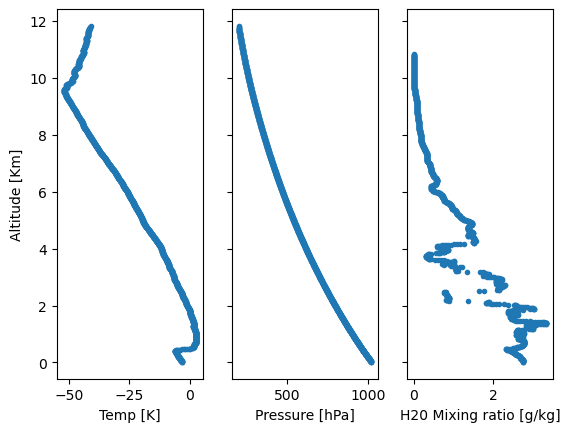

In [55]:
fig,ax  = plt.subplots(1,3,sharey=True)
ax[0].plot(sonde['Temperature'],sonde['GPS_Altitude']/1000.0,'.-')
ax[0].set_xlabel('Temp [K]')
ax[0].set_ylabel('Altitude [Km]')
#ax[1].figure()
ax[1].plot(sonde['Pressure'],sonde['GPS_Altitude']/1000.0,'.-')
ax[1].set_xlabel('Pressure [hPa]')
#plt.figure()
ax[2].plot(sonde['MixingRatio'],sonde['GPS_Altitude']/1000.0,'.-')
ax[2].set_xlabel('H20 Mixing ratio [g/kg]')

# Make ratios to standard atm

In [82]:
from scipy.interpolate import CubicSpline

In [97]:
sonde_air = gas_law(sonde['Pressure'],sonde['Temperature']+273.15)


In [109]:
g = (np.isfinite(sonde['GPS_Altitude']/1000.0)) & (np.isfinite(sonde_air))
fx_air = CubicSpline(np.flip(sonde['GPS_Altitude'][g]/1000.0),np.flip(sonde_air[g]),extrapolate=False)
sonde_air_int = fx_air(atm[:,0])

In [110]:
sonde_air_int

array([           nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan,            nan,            nan,
                  nan,            nan, 7.10398583e+18, 8.42232635e+18,
       9.82893249e+18, 1.10867550e+19, 1.23966307e+19, 1.38048357e+19,
       1.54279348e+19, 1.70959590e+19, 1.90921205e+19, 2.12332910e+19,
       2.37404216e+19,            nan])

In [111]:
sonde_air_ratio = sonde_air_int / atm[:,3]

In [130]:
ib = ~np.isfinite(sonde_air_ratio)

In [132]:
sonde_air_ratio[ib] = 1.0

In [133]:
sonde_air_ratio

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 0.96035277, 0.97822828,
       1.01385475, 1.01990407, 1.01989002, 1.0177315 , 1.02409262,
       1.01733865, 1.02012455, 1.02156948, 1.03051788, 1.        ])

In [113]:
sonde_h20 = h2o_mass_to_number_density(sonde['MixingRatio'],sonde['Pressure'],sonde['Temperature']+273.15)

In [114]:
sonde_h20

array([           nan,            nan,            nan, ...,
                  nan, 1.20748628e+17,            nan], shape=(3042,))

# plot our the vertical comparisons

In [116]:
#z(km)      p(mb)        T(K)    air(cm-3)    o3(cm-3)     o2(cm-3)    h2o(cm-3)    co2(cm-3)     no2(cm-3)

Text(0.5, 0, 'H2O')

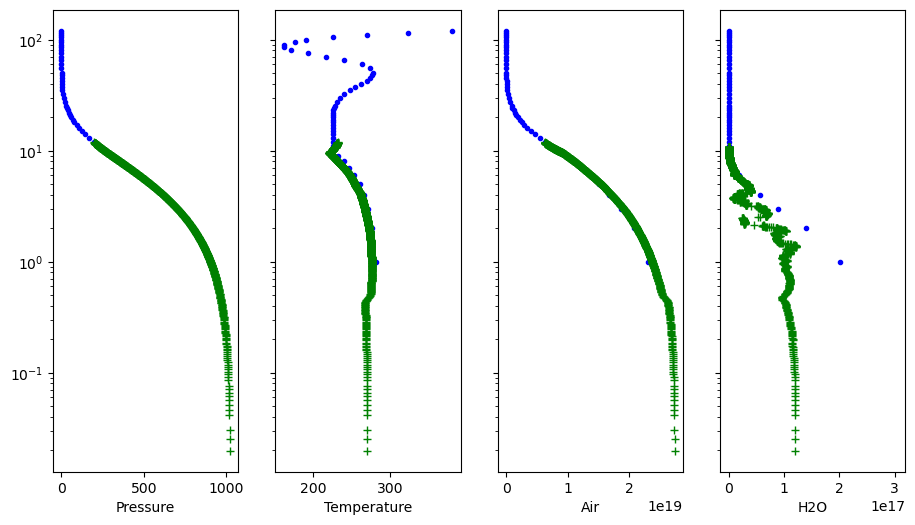

In [129]:
fig,ax = plt.subplots(1,4,sharey=True,figsize=(11,6))
ax[0].set_yscale('log')
ax[0].plot(atm[:,1],atm[:,0],'b.')
ax[0].plot(sonde['Pressure'],sonde['GPS_Altitude']/1000.0,'g+')
ax[0].set_xlabel('Pressure')

ax[1].plot(atm[:,2],atm[:,0],'b.')
ax[1].plot(sonde['Temperature']+273.15,sonde['GPS_Altitude']/1000.0,'g+')
ax[1].set_xlabel('Temperature')

ax[2].plot(atm[:,3],atm[:,0],'b.')
ax[2].plot(sonde_air,sonde['GPS_Altitude']/1000.0,'g+')
ax[2].set_xlabel('Air')

ax[3].plot(atm[:,6],atm[:,0],'b.')
ax[3].plot(sonde_h20,sonde['GPS_Altitude']/1000.0,'g+')
ax[3].set_xlabel('H2O')


# Build the atm profile from the sonde

In [ ]:
#z(km)      p(mb)        T(K)    air(cm-3)    o3(cm-3)     o2(cm-3)    h2o(cm-3)    co2(cm-3)     no2(cm-3)

In [135]:
atm_z = atm[:,0]
atm_air = atm[:,3]*sonde_air_ratio
atm_o3 = atm[:,4]*sonde_air_ratio
atm_o2 = atm[:,5]*sonde_air_ratio
atm_co2 = atm[:,7]*sonde_air_ratio
atm_no2 = atm[:,8]*sonde_air_ratio

In [136]:
gp = (np.isfinite(sonde['GPS_Altitude']/1000.0)) & (np.isfinite(sonde['Pressure']))
fx_air = CubicSpline(np.flip(sonde['GPS_Altitude'][gp]/1000.0),np.flip(sonde['Pressure'][gp]),extrapolate=False)
atm_p = fx_air(atm[:,0])
p_nan = ~np.isfinite(atm_p)
atm_p[p_nan] = atm[p_nan,1]

In [146]:
gt = (np.isfinite(sonde['GPS_Altitude']/1000.0)) & (np.isfinite(sonde['Temperature']))
fx_air = CubicSpline(np.flip(sonde['GPS_Altitude'][gt]/1000.0),np.flip(sonde['Temperature'][gt]+273.15),extrapolate=False)
atm_t = fx_air(atm[:,0])
t_nan = ~np.isfinite(atm_t)
atm_t[t_nan] = atm[t_nan,2]

In [141]:
gh = (np.isfinite(sonde['GPS_Altitude']/1000.0)) & (np.isfinite(sonde_h20))
fx_air = CubicSpline(np.flip(sonde['GPS_Altitude'][gh]/1000.0),np.flip(sonde_h20[gh]),extrapolate=False)
atm_h2o = fx_air(atm[:,0])
h_nan = ~np.isfinite(atm_h2o)
atm_h2o[h_nan] = atm[h_nan,6]

## Write the profile to file

In [144]:
fp

'/data2/ARCSIX/data/'

In [147]:
with open(fp+'atm_20240607.dat','w') as f:
    f.write('# Atmopshere profile based on afgss (subarctic summer) and drop sonde profile from G3 on 20240607\n')
    f.write('#     z(km)      p(mb)        T(K)    air(cm-3)    o3(cm-3)     o2(cm-3)    h2o(cm-3)    co2(cm-3)     no2(cm-3)\n')
    
    for z, p, t, air, o3, o2, h2o, co2, no2 in zip(
        atm_z, atm_p, atm_t, atm_air, atm_o3, atm_o2, atm_h2o, atm_co2, atm_no2
    ):
        line = (
            f"{z:11.3f}"
            f"{p:12.5f}"
            f"{t:12.3f}"
            f"{air:13.6E}"
            f"{o3:13.6E}"
            f"{o2:13.6E}"
            f"{h2o:13.6E}"
            f"{co2:13.6E}"
            f"{no2:13.6E}\n"
        )
        f.write(line)

# Plot out for the time period in question

(14.8, 16.0)

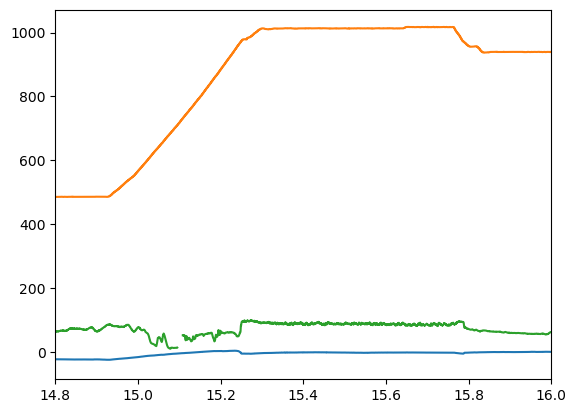

In [32]:
plt.figure()
plt.plot(met['Time_Start']/3600.0,met['Static_Air_Temp'])
plt.plot(met['Time_Start']/3600.0,met['Static_Pressure'])
plt.plot(met['Time_Start']/3600.0,met['Relative_Humidity'])
plt.xlim(14.8,16)

In [44]:
ival = np.argmin(abs(met['Time_Start']/3600.0 - 15.3))

In [45]:
ival

np.int64(7136)

In [46]:
met['Latitude'][ival],met['Longitude'][ival],

(np.float64(83.4881821), np.float64(-42.1048546))

# Now set the albedo

In [148]:
istart = np.argmin(abs(ssfr['time']/3600.0-15.3)) 
iend = np.argmin(abs(ssfr['time']/3600.0-15.7)) 

In [149]:
istart,iend

(np.int64(7136), np.int64(8576))

In [150]:
alb = ssfr['f_up']/ssfr['f_dn']

ValueError: operands could not be broadcast together with shapes (19627,381) (19627,380) 

In [153]:
ssfr['f_up'][istart,:]

array([3.62807729e-01, 3.50582403e-01, 3.64714366e-01, 3.70610029e-01,
       4.03961636e-01, 4.40248053e-01, 4.51141380e-01, 4.40834452e-01,
       4.43856833e-01, 4.34535704e-01, 4.09471238e-01, 4.15079460e-01,
       4.27845730e-01, 4.36689142e-01, 4.88473986e-01, 5.92193586e-01,
       6.67595986e-01, 6.80955249e-01, 7.00498645e-01, 7.16731190e-01,
       7.16286398e-01, 7.14821468e-01, 7.04982088e-01, 6.77424184e-01,
       6.58874846e-01, 6.80589428e-01, 7.20902446e-01, 7.48707130e-01,
       7.78471799e-01, 8.12196875e-01, 8.35006194e-01, 8.41910674e-01,
       8.43299462e-01, 8.49049419e-01, 8.45436679e-01, 8.34294843e-01,
       8.27009907e-01, 8.29666914e-01, 8.33310794e-01, 8.31810216e-01,
       8.14641130e-01, 7.94569303e-01, 7.92005895e-01, 7.99240314e-01,
       7.98500026e-01, 7.85191561e-01, 7.76419343e-01, 7.74289071e-01,
       7.70763688e-01, 7.51856401e-01, 7.30443193e-01, 7.26788077e-01,
       7.35701821e-01, 7.39414283e-01, 7.41880361e-01, 7.41715975e-01,
      

In [155]:
ssfr['wvl_up']

array([ 350.79367927,  354.07780647,  357.36270843,  360.64837667,
        363.93480269,  367.22197802,  370.50989416,  373.79854264,
        377.08791496,  380.37800264,  383.6687972 ,  386.96029016,
        390.25247301,  393.54533729,  396.8388745 ,  400.13307616,
        403.42793379,  406.72343889,  410.01958299,  413.3163576 ,
        416.61375422,  419.91176439,  423.21037961,  426.50959139,
        429.80939125,  433.10977071,  436.41072128,  439.71223447,
        443.01430181,  446.3169148 ,  449.62006495,  452.92374379,
        456.22794283,  459.53265358,  462.83786756,  466.14357627,
        469.44977125,  472.756444  ,  476.06358603,  479.37118886,
        482.67924401,  485.98774298,  489.2966773 ,  492.60603848,
        495.91581804,  499.22600748,  502.53659832,  505.84758208,
        509.15895027,  512.47069441,  515.78280601,  519.09527659,
        522.40809765,  525.72126072,  529.03475731,  532.34857894,
        535.66271711,  538.97716335,  542.29190916,  545.60694

In [157]:
from scipy.interpolate import make_interp_spline
interpolator = make_interp_spline(ssfr['wvl_up'], ssfr['f_up'], k=1, axis=1)
f_up_interp = interpolator(ssfr['wvl_dn'])  # Output shape: (19627, 380)

ValueError: Array must not contain infs or nans.

In [158]:
f_up_interp = np.empty((ssfr['f_up'].shape[0], len(ssfr['wvl_dn'])))

for i in range(ssfr['f_up'].shape[0]):
    row = ssfr['f_up'][i]
    valid = np.isfinite(row)
    
    if np.sum(valid) >= 2:  # Need at least 2 valid points to interpolate
        f_up_interp[i] = np.interp(ssfr['wvl_dn'], ssfr['wvl_up'][valid], row[valid])
    else:
        f_up_interp[i] = np.nan  # Keep row as NaN if completely empty

In [160]:
albedo = f_up_interp/ssfr['f_dn']

In [164]:
avg_albedo = np.nanmean(albedo[istart:iend,:],axis=0)

In [165]:
avg_albedo.shape

(380,)

(0.0, 1.0)

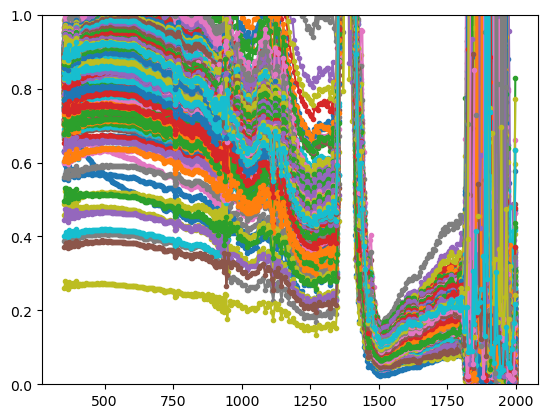

In [173]:
plt.figure()
plt.plot(ssfr['wvl_dn'],albedo[istart:iend,:].T,'.-')
plt.ylim(0,1)

(0.0, 0.01)

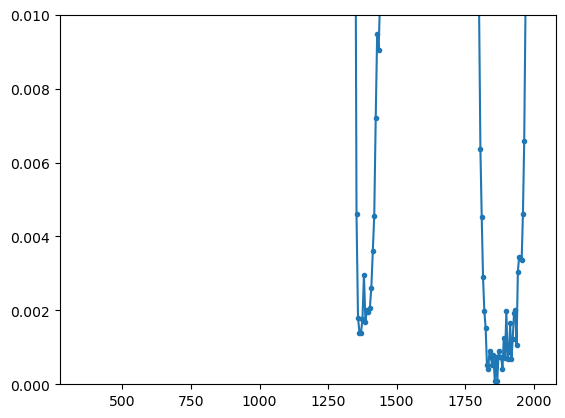

In [177]:
plt.figure()
plt.plot(ssfr['wvl_dn'],ssfr['f_dn'][istart,:].T,'.-')
plt.ylim(0,0.01)

In [185]:
ibad = ssfr['f_dn'][istart,:]<0.02

In [186]:
avg_albedo[ibad] = np.nan

In [187]:
avg_albedo

array([0.86456194, 0.90015999, 0.90556316, 0.87268038, 0.85948811,
       0.90946758, 0.87827352, 0.873649  , 0.88905399, 0.89919498,
       0.89330861, 0.87547883, 0.89669961, 0.91603406, 0.88827315,
       0.87854157, 0.89624794, 0.89973687, 0.89675575, 0.89291352,
       0.89941487, 0.90307269, 0.89499958, 0.90627941, 0.90887144,
       0.90186569, 0.89903598, 0.90321201, 0.90216633, 0.90275809,
       0.89924094, 0.90352286, 0.90497552, 0.90357172, 0.90298226,
       0.90613393, 0.90675923, 0.90580515, 0.90228832, 0.90359191,
       0.91009899, 0.9125272 , 0.90630177, 0.90736287, 0.90934171,
       0.9097451 , 0.91013528, 0.90774176, 0.90744082, 0.91005577,
       0.91253265, 0.91002308, 0.90949817, 0.9089808 , 0.90857676,
       0.90858691, 0.90779691, 0.90814994, 0.90809636, 0.90883182,
       0.90623145, 0.90660348, 0.90792111, 0.90775168, 0.90603717,
       0.90597555, 0.90762108, 0.9063782 , 0.90681416, 0.90451421,
       0.90456478, 0.90475999, 0.90730391, 0.90653268, 0.90728

## Now fill back up with extrapolated values

In [189]:
# now fill back up with extrapolated values

avg_albedo_good = np.interp(ssfr['wvl_dn'], ssfr['wvl_dn'][~ibad], avg_albedo[~ibad])

(0.0, 1.0)

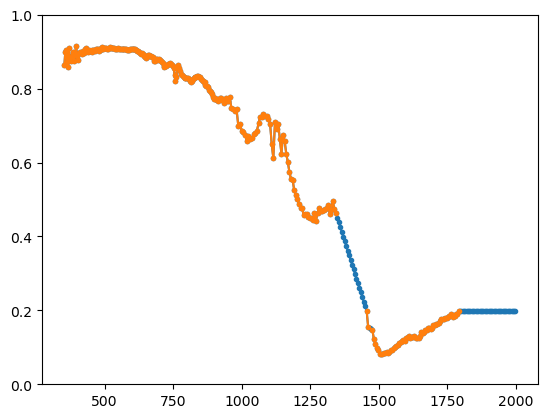

In [191]:
plt.figure()

plt.plot(ssfr['wvl_dn'],avg_albedo_good,'.-')
plt.plot(ssfr['wvl_dn'],avg_albedo,'.-')
plt.ylim(0,1)

## Now save the albedo file

In [194]:
wvl = np.arange(350,2201)

In [196]:
alb = np.interp(wvl,ssfr['wvl_dn'][~ibad], avg_albedo[~ibad])

In [199]:
with open(fp+'alb_20240607.dat','w') as f:
    f.write('# wvl[nm]    alb[unitless]\n')
    for i,w in enumerate(wvl):
        aa = alb[i]
        f.write(f'{w:10.6f}\t{aa:10.6f}\n')
    

In [198]:
alb[i]

np.float64(0.19737594870596387)

In [201]:
top_time = 54899
bot_time = 55042

In [202]:
itop = np.argmin(abs(met['Time_Start']-top_time))
ibot = np.argmin(abs(met['Time_Start']-bot_time))

In [204]:
met['GPS_Altitude'][itop]/1000.0,met['GPS_Altitude'][ibot]/1000.0

(np.float64(0.414), np.float64(0.156))

In [207]:
met['Solar_Zenith_Angle'][istart],met['Solar_Zenith_Angle'][iend]

(np.float64(60.7), np.float64(62.0))